<h1 style="text-align: center;">Used Car Price Prediction - Syarah.com</h1>
<h3 style="text-align: center;">Athiyyah Nisrina Husna & Firsa Adam</h3>

---

## **Section 0: Project Initialization**

### **0.1 Importing Library**

In [1]:
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
import joblib

from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error

# car_preprocessing harus dapat diimport sebelum model di-load
sys.path.append('../src')

pd.set_option('display.max_columns', None)

### **0.2 Global Configuration**

In [2]:
RANDOM_STATE = 42

# Palet warna (sama dengan notebook sebelumnya)
BLUE = '#3498db'   # warna utama
RED = '#e74c3c'    # warna pembanding / highlight

plt.rcParams.update({
    'figure.facecolor': 'white',
    'axes.facecolor': 'white',
    'axes.titlecolor': '#1a1a2e',
    'axes.labelcolor': '#1a1a2e',
    'xtick.color': '#444444',
    'ytick.color': '#444444',
    'axes.grid': True,
    'grid.color': '#d0d0d0',
    'axes.axisbelow': True,
})
sar_fmt = FuncFormatter(lambda x, _: f'{x:,.0f}')

# Data hasil 1_Data_Preparation.ipynb
df = pd.read_csv('../data/processed/cars_clean.csv')
df_nego = pd.read_csv('../data/processed/cars_negotiable.csv')
assert df.shape == (5487, 12), f"Shape cars_clean tidak sesuai: {df.shape}"
assert df_nego.shape == (2577, 11), f"Shape cars_negotiable tidak sesuai: {df_nego.shape}"

# Model final hasil 4_Machine_Learning_Modeling.ipynb
artifact = joblib.load('../models/used_car_price_model.pkl')
model = artifact['model']
FEATURES = artifact['features']
TARGET = 'Price'

# Split yang sama dengan notebook modeling
X_train, X_test, y_train, y_test = train_test_split(
    df[FEATURES], df[TARGET], test_size=0.2, random_state=RANDOM_STATE
)
assert len(X_train) == 4389 and len(X_test) == 1098

y_pred = pd.Series(model.predict(X_test), index=y_test.index)
assert y_pred.notna().all() and (y_pred > 0).all()

# Pastikan model yang di-load sama dengan model yang dievaluasi di notebook modeling
test_mape = mean_absolute_percentage_error(y_test, y_pred)
assert np.isclose(test_mape, artifact['test_metrics']['MAPE']), "MAPE test berbeda dengan hasil notebook modeling"

print(f"Train: {X_train.shape} | Test: {X_test.shape} | Negotiable: {df_nego.shape}")
print(f"MAPE test: {test_mape:.1%} | MAE test: {mean_absolute_error(y_test, y_pred):,.0f} SAR")

Train: (4389, 11) | Test: (1098, 11) | Negotiable: (2577, 11)
MAPE test: 18.3% | MAE test: 13,580 SAR


Notebook ini menggunakan model final dari `4_Machine_Learning_Modeling.ipynb`, yaitu XGBoost hasil tuning yang disimpan di `models/used_car_price_model.pkl`. Data dibagi ulang dengan `random_state` yang sama sehingga data test identik dengan data test pada notebook modeling. Sebagai validasi, MAPE model hasil load pada data test dicocokkan dengan MAPE yang tersimpan di dalam file model, sehingga seluruh analisis pada notebook ini dipastikan menggunakan model yang sama.

## **Section 1: Model Implementation**

### **1.1 Model Implementation**

Model diterapkan dalam dua tahap, sesuai rencana pada tahap Business Understanding.

**Tahap 1: Pengadaan stok dari listing Negotiable**

1. **Listing Negotiable masuk**

    Atribut kendaraan seperti merek, model, tahun, jarak tempuh, kapasitas mesin, dan kelengkapan fitur diambil langsung dari iklan yang sudah dipasang penjual, sehingga tidak perlu mengumpulkan data tambahan.

2. **Estimasi harga pasar dan rentang harga**

    Model menghasilkan estimasi harga pasar dalam SAR beserta rentang harga sebesar ±MAPE model pada data test.

3. **Prioritas dan penawaran awal**

    Listing diprioritaskan berdasarkan segmen estimasi harga yang paling akurat dan paling sesuai dengan stok Syarah. Penawaran awal disusun dari rentang harga dikurangi margin dan perkiraan biaya rekondisi.

4. **Inspeksi dan penawaran final**

    Mobil diinspeksi, lalu penawaran disesuaikan dengan kondisi aktual mobil sebelum menjadi penawaran final kepada penjual.

**Tahap 2: Penjual menjual mobil langsung ke Syarah**

Setelah Syarah sepenuhnya beralih menjadi penjual mobil bekas yang membeli stoknya langsung dari pemilik kendaraan, alur yang sama digunakan saat penjual mengisi data kendaraannya melalui aplikasi. Aplikasi langsung menampilkan estimasi harga awal beserta rentangnya, lalu estimasi tersebut disesuaikan dengan hasil inspeksi, margin, dan biaya rekondisi sebelum menjadi penawaran final.

Kode berikut menyusun langkah 2 menjadi satu fungsi `estimate_price`, yang menerima data mentah listing dan menghasilkan estimasi harga beserta batas bawah dan batas atasnya. Fungsi yang sama dapat digunakan pada aplikasi Streamlit di Tahap 2.

In [3]:
# Rentang harga berdasarkan MAPE data test, metrik utama pada tahap Business Understanding
RANGE_PCT = test_mape
assert 0 < RANGE_PCT < 1

# Proporsi listing data test yang harga aktualnya berada di dalam rentang
in_range = ((y_test >= y_pred * (1 - RANGE_PCT)) & (y_test <= y_pred * (1 + RANGE_PCT))).mean()
print(f"Rentang harga: ±{RANGE_PCT:.1%} dari estimasi | Listing data test di dalam rentang: {in_range:.1%}")


def estimate_price(X):
    """Menghasilkan estimasi harga pasar beserta rentang harganya.

    Args:
        X: DataFrame berisi kolom FEATURES (data mentah, tanpa preprocessing).

    Returns:
        DataFrame berisi Estimasi, Batas Bawah, dan Batas Atas dalam SAR.
    """
    missing_cols = set(FEATURES) - set(X.columns)
    assert not missing_cols, f"Kolom tidak lengkap: {missing_cols}"

    pred = pd.Series(model.predict(X[FEATURES]), index=X.index)
    return pd.DataFrame({
        'Estimasi (SAR)': pred,
        'Batas Bawah (SAR)': pred * (1 - RANGE_PCT),
        'Batas Atas (SAR)': pred * (1 + RANGE_PCT),
    })


# Contoh: tahap 1, listing Negotiable yang baru masuk
sample = df_nego.sample(5, random_state=RANDOM_STATE)
sample[['Make', 'Type', 'Year', 'Mileage', 'Options']].join(estimate_price(sample)).style.format(
    {'Mileage': '{:,.0f}', 'Estimasi (SAR)': '{:,.0f}', 'Batas Bawah (SAR)': '{:,.0f}', 'Batas Atas (SAR)': '{:,.0f}'},
    na_rep='kosong',
)

Rentang harga: ±18.3% dari estimasi | Listing data test di dalam rentang: 65.4%


,Make,Type,Year,Mileage,Options,Estimasi (SAR),Batas Bawah (SAR),Batas Atas (SAR)
1127,Chevrolet,Tahoe,2020,"26,500",Standard,"153,529","125,461","181,598"
932,Nissan,Armada,2008,"240,000",Semi Full,"20,446","16,708","24,184"
759,Mazda,CX9,2020,"12,000",Full,"126,421","103,308","149,534"
318,Toyota,Hilux,2016,"42,000",Full,"60,214","49,206","71,223"
1340,Hyundai,Accent,2018,"69,000",Standard,"35,375","28,908","41,843"


Rentang harga ditentukan dari MAPE model pada data test, yaitu **±18,3%** dari estimasi. MAPE dipilih karena merupakan metrik utama yang ditetapkan pada tahap Business Understanding, sehingga lebar rentang dapat dibaca langsung sebagai rata-rata kesalahan model. Rentang dalam persen juga menyesuaikan harga mobil: mobil murah mendapat rentang yang sempit dalam Riyal, sedangkan mobil mahal mendapat rentang yang lebih lebar. Sebagai contoh, Chevrolet Tahoe 2020 diestimasi sekitar 154.000 SAR dengan rentang 125.000–182.000 SAR.

Pada data test, sekitar 65,4% listing memiliki harga aktual di dalam rentang ini. Rentang tersebut memberi tim pengadaan maupun penjual gambaran ketidakpastian estimasi secara langsung, tanpa hanya bergantung pada satu angka.

### **1.2 Model Limitation**

| Aspek | Keterbatasan | Dampak |
|---|---|---|
| **Data** | Dataset hanya mencakup listing Syarah.com pada tahun 2021, dan `Price` merupakan harga yang ditawarkan penjual (asking price), bukan harga transaksi akhir. | Estimasi mencerminkan tingkat harga listing tahun 2021 dan masih perlu disesuaikan dengan harga transaksi serta perubahan harga pasar. |
| **Data** | Tidak ada informasi kondisi mobil, seperti riwayat kecelakaan, perawatan, atau kerusakan, dan sebagian nilai `Engine_Size` tidak konsisten dengan spesifikasi modelnya. | Mobil dengan kondisi buruk tetap diestimasi seperti mobil dengan kondisi wajar. Sepuluh error terbesar pada data test seluruhnya merupakan overestimate pada mobil murah (5.4). |
| **Data** | Jumlah listing per model mobil tidak merata. Sekitar 26% listing pada data test memiliki `Type` yang muncul kurang dari 20 kali di data train, dan 53 `Type` pada data Negotiable tidak ada sama sekali di data train. | Estimasi untuk model mobil yang jarang muncul kurang akurat, dengan MAPE di atas 24% dibandingkan 14,7% untuk model yang muncul minimal 50 kali. |
| **Fitur** | Varian atau trim di dalam satu `Type` hanya diwakili oleh `Options` (Standard, Semi Full, Full). | Varian dengan harga sangat berbeda, misalnya F-150 standar dan F-150 Raptor, tidak dapat dibedakan. |
| **Perilaku Model** | Error lebih tinggi pada listing dengan estimasi di bawah 20rb SAR dan listing tanpa jarak tempuh. Segmen < 20rb SAR memiliki MAPE 23,9% dengan 62,7% nilai prediksi lebih tinggi dari harga aktual, dan listing dengan `Mileage` kosong memiliki MAPE 28,6%. | Harga aktual pada kelompok ini lebih sering berada di luar rentang harga, sehingga estimasinya perlu dicek ulang sebelum digunakan untuk penawaran. |
| **Implementasi** | Listing Negotiable memiliki nilai kosong yang lebih banyak (`Mileage` 17,7%, `Engine_Size` 40,1%). Model juga tidak menyesuaikan diri dengan perubahan pasar secara otomatis. | Akurasi pada listing Negotiable kemungkinan lebih rendah dari hasil evaluasi pada data test, dan model perlu dilatih ulang secara berkala. |
| **Bisnis** | MAPE 18,3% lebih besar dari margin kotor tipikal penjualan mobil bekas, sekitar 10% (CarMax, 2021). | Estimasi model belum aman digunakan langsung sebagai harga beli final. Estimasi harus menjadi titik awal yang kemudian dikoreksi oleh inspeksi kondisi mobil. |

### **1.3 Cost Benefit Analysis**

Seperti dijelaskan pada tahap Business Understanding, error estimasi harga memiliki konsekuensi finansial yang berbeda tergantung arahnya. Overestimate membuat Syarah membeli mobil di atas harga pasar, sehingga margin saat dijual kembali tergerus. Kerugian ini bersifat langsung dan tidak dapat ditarik kembali setelah transaksi terjadi. Sebaliknya, underestimate membuat penawaran terlalu rendah sehingga berisiko ditolak penjual. Kerugiannya berupa hilangnya pasokan, tetapi sebagian masih dapat dipulihkan melalui negosiasi karena penjual dapat mengajukan harga balik.

Untuk mengukur manfaat model, error estimasi pada data test dibandingkan dengan cara penaksiran tanpa model, yaitu menggunakan median harga listing serupa di data train:

| Strategi | Cara Menaksir |
|---|---|
| **Median Make–Type–Year** | Median harga listing dengan merek, model, dan tahun yang sama. Cara ini mendekati penaksiran manual, yaitu membandingkan listing serupa satu per satu. Jika kelompok tidak ditemukan, digunakan Make–Type, lalu Make. |
| **Model XGBoost** | Model final hasil tuning. |

Setiap strategi diukur dengan total selisih harga ke arah overestimate dan underestimate. Selain itu, dihitung jumlah listing yang estimasinya melebihi harga aktual lebih dari 10%. Angka 10% digunakan sebagai acuan margin kotor penjualan mobil bekas, yaitu 10,1% pada CarMax tahun fiskal 2021 (CarMax, 2021). Jika penawaran beli disusun langsung dari estimasi pada listing seperti ini, keuntungan dari unit tersebut berisiko habis.

In [4]:
def median_baseline(X_train, y_train, X, group_levels):
    """Estimasi harga dengan median harga listing serupa di data train (tanpa model).

    Args:
        X_train: Fitur data train.
        y_train: Harga data train.
        X: Listing yang akan ditaksir.
        group_levels: Daftar kelompok dari paling spesifik ke paling umum. Jika kelompok
            tidak ditemukan, digunakan level berikutnya, lalu median global.

    Returns:
        Series estimasi harga (SAR), sejajar dengan X.
    """
    train = X_train.assign(Price=y_train)
    estimate = pd.Series(np.nan, index=X.index)
    for group in group_levels:
        median = train.groupby(group)['Price'].median().rename('_median')
        mask = estimate.isna()
        estimate[mask] = X.loc[mask, group].merge(median, left_on=group, right_index=True, how='left')['_median'].to_numpy()
    return estimate.fillna(y_train.median())


strategies = {
    'Median Make–Type–Year': median_baseline(X_train, y_train, X_test, [['Make', 'Type', 'Year'], ['Make', 'Type'], ['Make']]),
    'Model XGBoost': y_pred,
}
assert all(s.notna().all() and len(s) == len(y_test) for s in strategies.values())

In [5]:
GROSS_MARGIN = 0.10   # margin kotor penjualan mobil bekas (acuan: CarMax FY2021, 10,1%)


def calculate_exposure_dataframe(y_true, strategies, margin=GROSS_MARGIN):
    """Menghitung eksposur kerugian dari error estimasi harga untuk setiap strategi.

    Args:
        y_true: Harga listing aktual (SAR).
        strategies: Dictionary {nama strategi: Series estimasi harga}.
        margin: Margin kotor per unit. Overestimate di atas margin berarti
            penawaran berbasis estimasi berisiko membuat unit tersebut rugi.

    Returns:
        DataFrame ringkasan eksposur per strategi.
    """
    rows = []
    for name, pred in strategies.items():
        residual = y_true - pred                 # positif = underestimate, negatif = overestimate
        pct_error = residual / y_true
        rows.append({
            'Strategy': name,
            'MAPE': pct_error.abs().mean(),
            'MAE (SAR)': residual.abs().mean(),
            'Overestimate (SAR)': -residual[residual < 0].sum(),
            'Underestimate (SAR)': residual[residual > 0].sum(),
            'Listing Error ±20% (%)': (pct_error.abs() <= 0.20).mean() * 100,
            'Overestimate > Margin': (pct_error < -margin).sum(),
        })
    result = pd.DataFrame(rows).set_index('Strategy')
    # Rata-rata eksposur overestimate jika diterapkan pada 1.000 unit (target stok Syarah)
    result['Overestimate per 1.000 Unit (SAR)'] = result['Overestimate (SAR)'] / len(y_true) * 1_000
    return result


cost_df = calculate_exposure_dataframe(y_test, strategies)
assert len(cost_df) == len(strategies)
cost_df.style.format({
    'MAPE': '{:.1%}', 'MAE (SAR)': '{:,.0f}', 'Overestimate (SAR)': '{:,.0f}',
    'Underestimate (SAR)': '{:,.0f}', 'Listing Error ±20% (%)': '{:.1f}',
    'Overestimate per 1.000 Unit (SAR)': '{:,.0f}',
})

,MAPE,MAE (SAR),Overestimate (SAR),Underestimate (SAR),Listing Error ±20% (%),Overestimate > Margin,Overestimate per 1.000 Unit (SAR)
Strategy,,,,,,,
Median Make–Type–Year,36.9%,"16,841","11,010,950","7,480,405",66.7,358,"10,028,187"
Model XGBoost,18.3%,"13,580","5,765,207","9,145,911",69.6,320,"5,250,644"


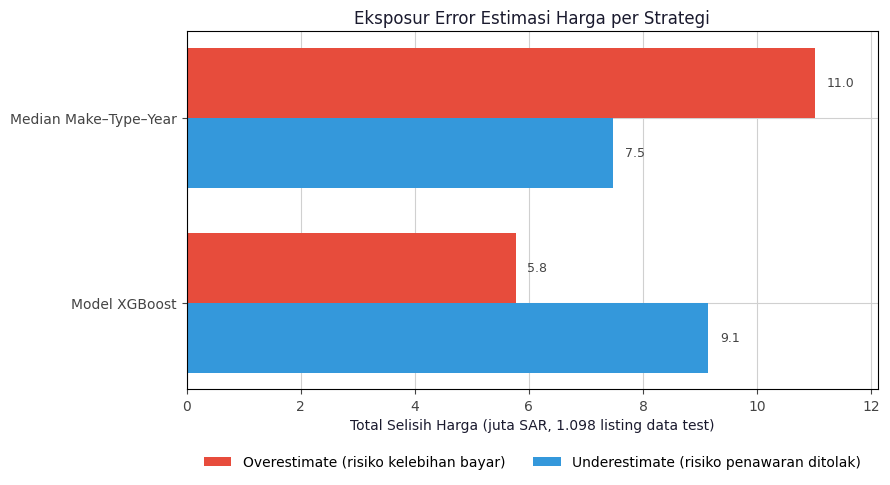

In [6]:
# Eksposur dalam juta SAR
exposure = cost_df[['Overestimate (SAR)', 'Underestimate (SAR)']] / 1e6

fig, ax = plt.subplots(figsize=(9, 5))
y_pos = np.arange(len(exposure))
height = 0.38

ax.barh(y_pos - height / 2, exposure['Overestimate (SAR)'], height=height, color=RED, label='Overestimate (risiko kelebihan bayar)')
ax.barh(y_pos + height / 2, exposure['Underestimate (SAR)'], height=height, color=BLUE, label='Underestimate (risiko penawaran ditolak)')
for i, (over, under) in enumerate(exposure.to_numpy()):
    ax.text(over + 0.2, i - height / 2, f'{over:.1f}', va='center', fontsize=9, color='#444444')
    ax.text(under + 0.2, i + height / 2, f'{under:.1f}', va='center', fontsize=9, color='#444444')

ax.set_yticks(y_pos, exposure.index)
ax.invert_yaxis()
ax.set_xlabel('Total Selisih Harga (juta SAR, 1.098 listing data test)')
ax.set_title('Eksposur Error Estimasi Harga per Strategi')
ax.set_xlim(0, exposure.to_numpy().max() * 1.1)
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.15), ncol=2, frameon=False)

plt.tight_layout()
plt.show()

Model XGBoost menghasilkan eksposur overestimate sekitar 5,8 juta SAR pada 1.098 listing data test, turun sekitar 48% dibandingkan Median Make–Type–Year (11,0 juta SAR). Jika pola error ini berlaku pada 1.000 mobil yang ditargetkan Syarah, potensi kelebihan bayar turun dari sekitar 10,0 juta SAR menjadi sekitar 5,3 juta SAR. Karena overestimate merupakan kerugian langsung, penurunan inilah manfaat finansial utama dari penggunaan model. Secara keseluruhan, total selisih harga juga turun dari sekitar 18,5 juta SAR menjadi 14,9 juta SAR, dan proporsi listing dengan error dalam ±20% naik dari 66,7% menjadi 69,6%.

Di sisi lain, eksposur underestimate model (9,1 juta SAR) lebih tinggi dibandingkan Median Make–Type–Year (7,5 juta SAR). Hal ini sejalan dengan temuan pada notebook modeling, di mana proporsi underestimate (51,7%) sedikit lebih tinggi dibandingkan overestimate. Arah error ini lebih aman bagi Syarah, karena penawaran yang terlalu rendah masih dapat dinaikkan melalui negosiasi, sedangkan kelebihan bayar tidak dapat ditarik kembali.

Meskipun demikian, sebanyak 320 listing (sekitar 29%) masih memiliki overestimate lebih dari 10%, hanya sedikit lebih rendah dibandingkan Median Make–Type–Year (358 listing). Dengan MAPE yang lebih besar dari margin kotor, estimasi model belum dapat langsung dijadikan harga beli final. Model memberikan titik awal yang lebih baik dibandingkan penaksiran berbasis listing serupa, tetapi tetap perlu dikoreksi oleh inspeksi kondisi mobil dan dibaca bersama rentang harganya.

### **1.4 Goals: Stock Procurement**

Pada tahap Business Understanding, model diharapkan dapat mempercepat pengadaan stok, menjaga konsistensi harga beli antar unit, dan mengurangi risiko penawaran yang terlalu tinggi maupun terlalu rendah. Tujuan ketiga sudah diukur pada bagian 1.3. Bagian ini mengevaluasi dua tujuan lainnya, yaitu seberapa akurat estimasi pada setiap segmen harga, dan berapa banyak listing Negotiable yang dapat langsung diproses untuk mencapai target stok lebih dari 1.000 mobil (Wamda, 2021).

Segmen harga ditentukan berdasarkan **harga prediksi**, sama seperti pada notebook modeling (5.3), karena harga aktual listing Negotiable tidak diketahui. Dengan cara ini, akurasi setiap segmen pada data test dapat langsung digunakan sebagai acuan untuk listing Negotiable pada segmen yang sama.

In [7]:
PRICE_BINS = [0, 20_000, 50_000, 100_000, 200_000, np.inf]
PRICE_LABELS = ['< 20rb', '20rb–50rb', '50rb–100rb', '100rb–200rb', '≥ 200rb']

# Segmen berdasarkan harga prediksi, karena harga aktual listing Negotiable tidak diketahui
test_segment = pd.cut(y_pred, bins=PRICE_BINS, labels=PRICE_LABELS, right=False)
assert test_segment.notna().all()

pct_error = ((y_test - y_pred) / y_test).abs()
segment_summary = (
    pd.DataFrame({'pct_error': pct_error, 'segment': test_segment})
    .groupby('segment', observed=True)
    .agg(
        Jumlah=('pct_error', 'size'),
        MAPE=('pct_error', 'mean'),
        Error_20=('pct_error', lambda s: (s <= 0.20).mean() * 100),
    )
    .rename(columns={'Error_20': 'Error ±20% (%)'})
)
segment_summary.index.name = 'Segmen Estimasi Harga'
assert segment_summary['Jumlah'].sum() == len(y_test)
segment_summary.style.format({'MAPE': '{:.1%}', 'Error ±20% (%)': '{:.1f}'})

,Jumlah,MAPE,Error ±20% (%)
Segmen Estimasi Harga,,,
< 20rb,59,23.9%,55.9
20rb–50rb,398,19.3%,70.6
50rb–100rb,399,17.4%,70.9
100rb–200rb,186,16.1%,68.8
≥ 200rb,56,18.7%,69.6


Empat dari lima segmen memiliki MAPE di bawah target 20%, dengan akurasi terbaik pada segmen 100rb–200rb (MAPE 16,1%) dan 50rb–100rb (MAPE 17,4%). Pada keempat segmen ini, sekitar 69–71% listing memiliki error dalam ±20%. Segmen dengan estimasi di bawah 20rb SAR menjadi satu-satunya segmen di atas target, dengan MAPE 23,9% dan hanya 55,9% listing yang error-nya dalam ±20%.

Hasil ini sama dengan analisis segmen harga pada notebook modeling (5.3), karena keduanya mengelompokkan listing berdasarkan harga prediksi.

In [8]:
STOCK_TARGET = 1_000   # target stok Syarah setelah pendanaan Series B (Wamda, 2021)

nego_result = df_nego.join(estimate_price(df_nego))
nego_result['Segmen Harga'] = pd.cut(nego_result['Estimasi (SAR)'], bins=PRICE_BINS, labels=PRICE_LABELS, right=False)
assert len(nego_result) == len(df_nego)
assert nego_result['Segmen Harga'].notna().all()

procurement = (
    nego_result.groupby('Segmen Harga', observed=True)
    .agg(Jumlah=('Estimasi (SAR)', 'size'), Median_Estimasi=('Estimasi (SAR)', 'median'))
    .rename(columns={'Median_Estimasi': 'Median Estimasi (SAR)'})
    .join(segment_summary['MAPE'].rename('MAPE Data Test'))
)
display(procurement.style.format({'Median Estimasi (SAR)': '{:,.0f}', 'MAPE Data Test': '{:.1%}'}))

# Segmen dengan MAPE data test di bawah target 20%
accurate_segments = segment_summary.index[segment_summary['MAPE'] <= 0.20]
n_ready = nego_result['Segmen Harga'].isin(accurate_segments).sum()
print(f"Segmen dengan MAPE <= 20%: {list(accurate_segments)}")
print(f"Listing pada segmen tersebut: {n_ready:,} | Target stok: {STOCK_TARGET:,} | Cakupan: {n_ready / STOCK_TARGET:.0%}")

,Jumlah,Median Estimasi (SAR),MAPE Data Test
Segmen Harga,,,
< 20rb,330,"14,847",23.9%
20rb–50rb,927,"34,558",19.3%
50rb–100rb,870,"64,892",17.4%
100rb–200rb,349,"126,232",16.1%
≥ 200rb,101,"245,651",18.7%


Segmen dengan MAPE <= 20%: ['20rb–50rb', '50rb–100rb', '100rb–200rb', '≥ 200rb']
Listing pada segmen tersebut: 2,247 | Target stok: 1,000 | Cakupan: 225%


Model memproses seluruh 2.577 listing Negotiable sekaligus dengan aturan yang sama, sehingga mobil dengan atribut yang sama selalu mendapatkan estimasi yang sama, tanpa bergantung pada siapa yang menaksir. Dari jumlah tersebut, **2.247 listing (sekitar 87%) berada pada segmen dengan MAPE di bawah 20%**, atau sekitar 225% dari target stok 1.000 mobil. Artinya, meskipun tidak semua penjual menerima penawaran, Syarah sudah memiliki kandidat pasokan yang lebih besar dari target hanya dari listing Negotiable di platformnya sendiri.

Kandidat terbesar berada pada segmen 20rb–100rb SAR (1.797 listing), dengan median estimasi sekitar 35.000 SAR dan 65.000 SAR. Rentang ini sejalan dengan rata-rata harga mobil yang terjual secara online oleh Syarah, yaitu sekitar 50.000 SAR (SAR 300 juta dari sekitar 6.000 mobil; Wamda, 2021), sehingga kandidat pasokan tersebut berada pada segmen harga yang sudah biasa dijual oleh Syarah. Sementara itu, 330 listing dengan estimasi di bawah 20rb SAR tetap dapat menjadi pasokan tambahan, tetapi estimasinya perlu dicek ulang sebelum ditawar.

## **Section 2: Conclusion**

### **2.1 Model Conclusion**

Best model: **XGBoost (Tuned) dengan transformasi log1p pada target**

<div align="center">

| Metric | **Test Set (Final)** | Target |
| :--- | :---: | :---: |
| **MAPE** | **18,3%** | ≤ 20% |
| **MAE** | **13.580 SAR** | < Linear Regression (15.818 SAR) |
| **RMSE** | **30.253 SAR** | – |
| **R²** | **0,837** | ≥ 0,82 |
| **Underestimate / Overestimate** | **51,7% / 48,3%** | 45–55% |

</div>

\
Model machine learning dikembangkan untuk menaksir harga pasar mobil bekas berdasarkan atribut kendaraan, sehingga Syarah dapat **memberikan estimasi harga untuk listing Negotiable yang tidak mencantumkan harga**. Model XGBoost hasil tuning memenuhi seluruh kriteria keberhasilan yang ditetapkan pada tahap Business Understanding. Rata-rata estimasi meleset sekitar 18% atau sekitar 13,6 ribu SAR dari harga listing, lebih baik dibandingkan Linear Regression (MAPE 21,8%), dan R² sebesar 0,837 melampaui R² 0,82 yang dilaporkan Gollapalli et al. (2023) pada dataset yang sama. Arah error juga seimbang, sehingga model tidak secara sistematis membuat Syarah membayar terlalu mahal ataupun menawar terlalu rendah.

Model bekerja dengan baik pada listing dengan estimasi harga 20rb SAR ke atas, yang mencakup sekitar 95% listing data test, dengan MAPE antara 16,1% dan 19,3%. Error lebih tinggi pada listing dengan estimasi di bawah 20rb SAR (MAPE 23,9%), model mobil yang jarang muncul, dan listing tanpa jarak tempuh. Ketidakpastian ini ditampilkan kepada pengguna melalui rentang harga, yaitu ±18,3% dari estimasi.

Berdasarkan analisis SHAP, faktor-faktor yang paling memengaruhi harga adalah:

* **Umur Mobil (`Car_Age`, faktor utama):** Rata-rata dampaknya sekitar ±35% terhadap harga. Mobil yang lebih tua menurunkan harga hingga sekitar 70%, sedangkan mobil yang lebih baru menaikkannya.

* **Model Mobil (`Type`):** Rata-rata dampaknya sekitar ±24%. Model dengan rata-rata harga tinggi dapat menaikkan harga hingga sekitar 90%.

* **Kapasitas Mesin (`Engine_Size`):** Rata-rata dampaknya sekitar ±18%. Mesin yang lebih besar menaikkan harga.

* **Merek (`Make`) dan Jarak Tempuh (`Mileage`):** Masing-masing berdampak sekitar ±11%. Merek premium dapat menaikkan harga lebih dari dua kali lipat, sedangkan jarak tempuh tinggi menurunkan harga.

Sementara itu, `Region` dan `Color` berdampak kurang dari 2%, sehingga lokasi penjualan dan warna mobil hampir tidak memengaruhi harga.

### **2.2 Business Conclusion**

Harga mobil bekas di Syarah.com tidak ditentukan secara acak, melainkan mengikuti pola yang dapat dipelajari dari atribut kendaraan, terutama umur, model, kapasitas mesin, merek, dan jarak tempuh. Dengan mempelajari pola tersebut, model dapat menggantikan penaksiran manual listing Negotiable satu per satu dengan estimasi yang cepat dan konsisten.

Dibandingkan penaksiran berbasis median harga listing serupa (Make–Type–Year), model **menurunkan eksposur kelebihan bayar sekitar 48%, dari sekitar 11,0 juta SAR menjadi 5,8 juta SAR** pada data test, atau dari sekitar 10,0 juta SAR menjadi 5,3 juta SAR jika diterapkan pada 1.000 unit. Dari 2.577 listing Negotiable, **2.247 listing berada pada segmen harga dengan MAPE di bawah 20%**, melampaui target stok 1.000 mobil.

Namun, karena error model masih lebih besar dari margin kotor tipikal penjualan mobil bekas, estimasi model berperan sebagai acuan awal penawaran, bukan harga beli final. Nilai bisnis model diperoleh ketika estimasi digabungkan dengan rentang harga, inspeksi kondisi mobil, dan proses negosiasi.

## **Section 3: Recommendation**

### **3.1 Model Recommendation**

Berdasarkan hasil evaluasi dan keterbatasan model, akurasi model dapat ditingkatkan dengan menambahkan data yang secara langsung menjawab sumber error terbesar:

*   **Data Kondisi dan Riwayat Kendaraan:** Error terbesar pada data test berasal dari mobil yang harganya jauh di bawah spesifikasinya, yang kemungkinan disebabkan oleh kondisi buruk atau riwayat kecelakaan. Syarah sudah memiliki layanan laporan riwayat kendaraan Mojaz dan melakukan inspeksi pada mobil bekas yang dijualnya secara langsung, sehingga hasilnya dapat dijadikan fitur, misalnya jumlah kecelakaan atau skor kondisi hasil inspeksi.

*   **Harga Transaksi Aktual:** Model saat ini mempelajari harga listing yang ditawarkan penjual. Setelah model digunakan, harga beli dan harga jual akhir dari setiap transaksi Syarah perlu dicatat dan digunakan untuk melatih ulang model, sehingga estimasi semakin mendekati harga yang benar-benar disepakati.

*   **Varian atau Trim Kendaraan:** Menambahkan informasi trim, misalnya GL, LE, atau Raptor, akan membantu model membedakan varian dengan harga yang sangat berbeda di dalam satu model mobil. Informasi ini sebagian sudah tercantum pada URL iklan, misalnya TXL pada Toyota Prado, sehingga dapat diekstrak dari kolom `Link` atau dijadikan isian wajib pada form.

*   **Data untuk Kategori Langka dan Mobil Murah:** Model mobil yang jarang muncul (MAPE di atas 24%) dan listing dengan estimasi di bawah 20rb SAR (MAPE 23,9%) memiliki error tertinggi. Penambahan data listing pada kelompok ini dapat dipertimbangkan agar estimasinya lebih tepat.

*   **Pelatihan Ulang dan Monitoring Berkala:** Model perlu dilatih ulang secara berkala, misalnya setiap kuartal, karena harga mobil bekas berubah mengikuti kondisi pasar. Performa model juga perlu dipantau menggunakan harga transaksi aktual, termasuk proporsi kategori baru yang tidak dikenal model, seperti 53 model mobil pada data Negotiable yang tidak ada di data train.

### **3.2 Business Recommendation**

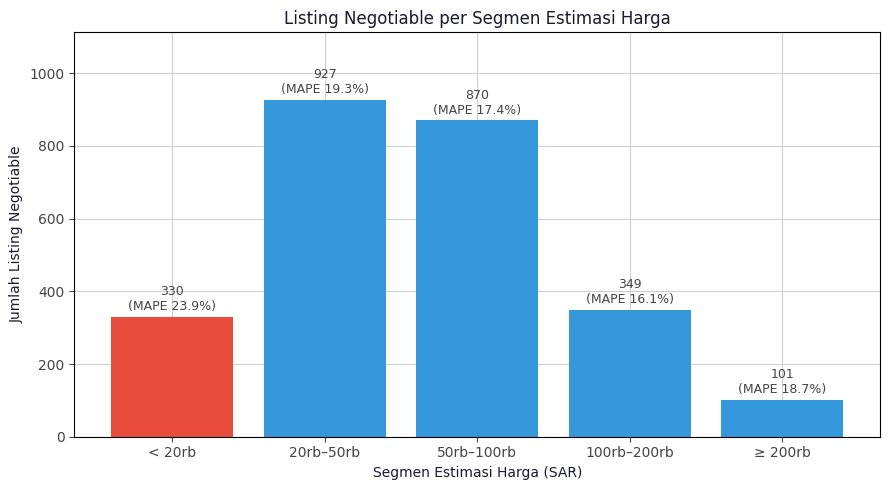

In [9]:
segment_count = nego_result['Segmen Harga'].value_counts().reindex(PRICE_LABELS)
colors = [BLUE if seg in accurate_segments else RED for seg in segment_count.index]

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar(segment_count.index, segment_count.values, color=colors)
for bar, seg in zip(bars, segment_count.index):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 10,
            f"{bar.get_height():,.0f}\n(MAPE {segment_summary.loc[seg, 'MAPE']:.1%})",
            ha='center', va='bottom', fontsize=9, color='#444444')

ax.set_ylim(0, segment_count.max() * 1.2)
ax.set_xlabel('Segmen Estimasi Harga (SAR)')
ax.set_ylabel('Jumlah Listing Negotiable')
ax.set_title('Listing Negotiable per Segmen Estimasi Harga')

plt.tight_layout()
plt.show()

Sebagian besar listing Negotiable berada pada segmen 20rb–100rb SAR (1.797 dari 2.577 listing), yang juga memiliki MAPE di bawah target 20% dan sejalan dengan rata-rata harga mobil yang terjual secara online oleh Syarah. Sebaliknya, segmen di bawah 20rb SAR (330 listing) menjadi satu-satunya segmen dengan MAPE di atas target.

Berdasarkan temuan tersebut, Syarah dapat menerapkan **alur pengadaan stok berbasis estimasi harga** sebagai berikut:

1. **Prioritaskan listing pada segmen 20rb–100rb SAR**

    Hubungi penjual pada kelompok ini terlebih dahulu, karena jumlahnya paling banyak, MAPE-nya di bawah target 20%, dan sesuai dengan segmen yang sudah biasa dijual Syarah.

2. **Gunakan rentang harga sebagai batas negosiasi**

    Susun penawaran awal dari batas bawah rentang harga, lalu kurangi dengan margin dan perkiraan biaya rekondisi. Selama negosiasi, penawaran tidak melebihi estimasi harga dikurangi margin, sehingga risiko kelebihan bayar tetap terkendali.

3. **Jadikan inspeksi dan laporan Mojaz sebagai syarat penawaran final**

    Karena error model masih lebih besar dari margin kotor, setiap penawaran harus dikoreksi dengan hasil inspeksi dan riwayat kendaraan sebelum menjadi harga beli final.

4. **Lakukan pengecekan tambahan pada kondisi dengan error tinggi**

    | Kondisi | Penanganan |
    | :--- | :--- |
    | `Mileage` kosong | Minta penjual melengkapi jarak tempuh, lalu hitung ulang estimasi. Listing dengan `Mileage` terisi memiliki MAPE 17,4%, dibandingkan 28,6% jika kosong. |
    | Model mobil langka | Bandingkan dengan listing serupa secara manual oleh tim pricing sebelum menawar. |
    | Estimasi < 20rb SAR | Lakukan inspeksi sebelum menawar, karena model cenderung memprediksi lebih mahal pada segmen ini. |
    | Mobil ≥ 200rb SAR | MAPE segmen ini di bawah 20%, tetapi jumlah datanya paling sedikit. Libatkan penilai khusus mobil mewah sebelum penawaran final. |

5. **Wajibkan data penting pada form penjualan (Tahap 2)**

    Saat penjual menjual mobil langsung ke Syarah, jadikan `Mileage` dan `Engine_Size` sebagai isian wajib. Nilai kosong pada kedua kolom ini merupakan salah satu penyebab utama estimasi yang kurang akurat.

6. **Catat hasil setiap penawaran**

    Simpan estimasi, penawaran, status diterima atau ditolak, dan harga final setiap transaksi. Data ini digunakan untuk mengukur dampak model secara nyata, menyesuaikan margin penawaran, dan melatih ulang model dengan harga transaksi aktual.

Alur ini memungkinkan Syarah mengumpulkan stok lebih cepat dari listing yang sudah ada di platformnya sendiri, dengan harga beli yang konsisten antar unit dan risiko kelebihan bayar yang lebih terkendali.

Referensi:
- CarMax. (2021, 1 April). CarMax reports fourth quarter and fiscal year 2021 results. Business Wire. https://www.businesswire.com/news/home/20210401005181/en
- Gollapalli, M., Alqahtani, T. A., Alhamed, D. H., Alnassar, M. R., Alajmi, A. M., Alali, Y. H., Abdulqader, M. M., & Saadeldeen, A. (2023). Intelligent modelling techniques for predicting used cars prices in Saudi Arabia. Mathematical Modelling of Engineering Problems, 10(1), 139–148. https://doi.org/10.18280/mmep.100115
- Wamda. (2021, 29 Agustus). Syarah raises $20 million in Series B round. https://www.wamda.com/2021/08/syarah-raises-20-million-series-b-round